### My Question
## What is the probability of rolling that it lands on 15 on a D-20?

### My Study
Describe your simulation here:
1. Trying to find out what the chances of rolling a 15 on D-20 and seeing how many tries it takes for it to land on the 15.
2. One trial will look like it might land near a 15 on the second or third roll, but the outcome of it is that it might take more rolls or fewer rolls to land a 15.
3. I'm hoping it'll take fewer rolls to land on a 15, but the result might be more than I originally thought. 

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random

In [18]:
rng = np.random.default_rng()

### Sample Space

In [15]:
sample_space = ["Dice rolls", "D-20"]

print("Sample space for dice rolls:", sample_space)
print("Number of possible outcomes:", len(sample_space))

Sample space for dice rolls: ['Dice rolls', 'D-20']
Number of possible outcomes: 2


In [2]:
dice_space = list(range(1, 20))

print("Sample space for dice rolls:", dice_space)
print("Number of possible outcomes:", len(dice_space))

Sample space for dice rolls: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Number of possible outcomes: 19


In [3]:
two_dice_space = []
for first in range(1, 20):
    for second in range(1, 20):
        two_dice_space.append((first, second))

print("Sample space for rolling two d-20s:", two_dice_space)
print("Number of possible outcomes:", len(two_dice_space))

Sample space for rolling two d-20s: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (1, 10), (1, 11), (1, 12), (1, 13), (1, 14), (1, 15), (1, 16), (1, 17), (1, 18), (1, 19), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9), (2, 10), (2, 11), (2, 12), (2, 13), (2, 14), (2, 15), (2, 16), (2, 17), (2, 18), (2, 19), (3, 1), (3, 2), (3, 3), (3, 4), (3, 5), (3, 6), (3, 7), (3, 8), (3, 9), (3, 10), (3, 11), (3, 12), (3, 13), (3, 14), (3, 15), (3, 16), (3, 17), (3, 18), (3, 19), (4, 1), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6), (4, 7), (4, 8), (4, 9), (4, 10), (4, 11), (4, 12), (4, 13), (4, 14), (4, 15), (4, 16), (4, 17), (4, 18), (4, 19), (5, 1), (5, 2), (5, 3), (5, 4), (5, 5), (5, 6), (5, 7), (5, 8), (5, 9), (5, 10), (5, 11), (5, 12), (5, 13), (5, 14), (5, 15), (5, 16), (5, 17), (5, 18), (5, 19), (6, 1), (6, 2), (6, 3), (6, 4), (6, 5), (6, 6), (6, 7), (6, 8), (6, 9), (6, 10), (6, 11), (6, 12), (6, 13), (6, 14), (6, 15), (6, 16), (6, 17), (6, 18), 

# Simulation

In [1]:
sample_space = list(range(1, 21))
favorable_outcomes = [15]
probability = len(favorable_outcomes) / len(sample_space)

In [2]:
print("Sample space for a D-20 roll:", sample_space)
print("Number of possible outcomes:", len(sample_space))
print(f"Probability of rolling a 15: {probability} (or {probability * 100}%)")

Sample space for a D-20 roll: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Number of possible outcomes: 20
Probability of rolling a 15: 0.05 (or 5.0%)


In [3]:
two_d20_space = []
for first in range(1, 21):
    for second in range(1, 21):
        two_d20_space.append((first, second))

In [4]:
print("Sample space for rolling two D20s (first 10 shown):", two_d20_space[:10])
print("Number of possible outcomes:", len(two_d20_space))

Sample space for rolling two D20s (first 10 shown): [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (1, 10)]
Number of possible outcomes: 400


## Theoretical Probability

In [5]:
sample_space = list(range(1, 21))
outcomes_in_event = 1
total_outcomes = len(sample_space)

In [6]:
theoretical_p_15 = outcomes_in_event / total_outcomes
print("Theoretical P(Rolling a 15) =", theoretical_p_15)

Theoretical P(Rolling a 15) = 0.05


In [28]:
def roll_dice(number_of_rolls):
    values = rng.integers(1, 21, size=number_of_rolls)
    labels = np.where(values == 15, "Hit (15)", "Miss")

    return pd.DataFrame({
        "roll_number": np.arange(1, number_of_rolls + 1),
        "value": values,
        "outcome": labels
    })
rolls_10 = roll_dice(10)
rolls_10

,roll_number,value,outcome
0,1,14,Miss
1,2,17,Miss
2,3,6,Miss
3,4,11,Miss
4,5,7,Miss
5,6,4,Miss
6,7,6,Miss
7,8,4,Miss
8,9,3,Miss
9,10,2,Miss


In [29]:
counts_10 = rolls_10["outcome"].value_counts()

print("Counts of each outcome:")
print(counts_10)
print()
print("Total number of rolls:", counts_10.sum())

Counts of each outcome:
outcome
Miss    10
Name: count, dtype: int64

Total number of rolls: 10


In [31]:
hit_count = (rolls_10["outcome"] == "Hit (15)").sum()
total = len(rolls_10)

In [32]:
relative_freq_15 = hit_count / total

print(f"Hit (15) came up {hit_count} times out of {total} rolls.")
print(f"Relative frequency of rolling a 15 = {hit_count}/{total} = {relative_freq_15}")
print(f"Theoretical probability of rolling a 15 = {theoretical_p_15}")

Hit (15) came up 0 times out of 10 rolls.
Relative frequency of rolling a 15 = 0/10 = 0.0
Theoretical probability of rolling a 15 = 0.05


In [33]:
results = []

for n in [10, 100, 1_000, 10_000, 100_000]:
    rolls = roll_dice(n)
    hits = (rolls["outcome"] == "Hit (15)").sum()
    rel_freq = hits / n
    results.append({
        "number_of_rolls": n,
        "hits_count": hits,
        "relative_freq_15": round(rel_freq, 4),
        "distance_from_0.05": round(abs(rel_freq - 0.05), 4)
    })

In [34]:
results_table = pd.DataFrame(results)
results_table

,number_of_rolls,hits_count,relative_freq_15,distance_from_0.05
0,10,0,0.0000,0.0500
1,100,5,0.0500,0.0000
2,1000,38,0.0380,0.0120
3,10000,525,0.0525,0.0025
4,100000,5028,0.0503,0.0003


In [35]:
rolls = roll_dice(2000)
rolls["hits_so_far"] = (rolls["value"] == 15).astype(int).cumsum()
rolls["relative_freq_so_far"] = rolls["hits_so_far"] / rolls["roll_number"]

In [36]:
rolls.head(10)

,roll_number,value,outcome,hits_so_far,relative_freq_so_far
0,1,15,Hit (15),1,1.000000
1,2,4,Miss,1,0.500000
2,3,19,Miss,1,0.333333
3,4,18,Miss,1,0.250000
4,5,17,Miss,1,0.200000
5,6,6,Miss,1,0.166667
6,7,4,Miss,1,0.142857
7,8,20,Miss,1,0.125000
8,9,5,Miss,1,0.111111
9,10,3,Miss,1,0.100000


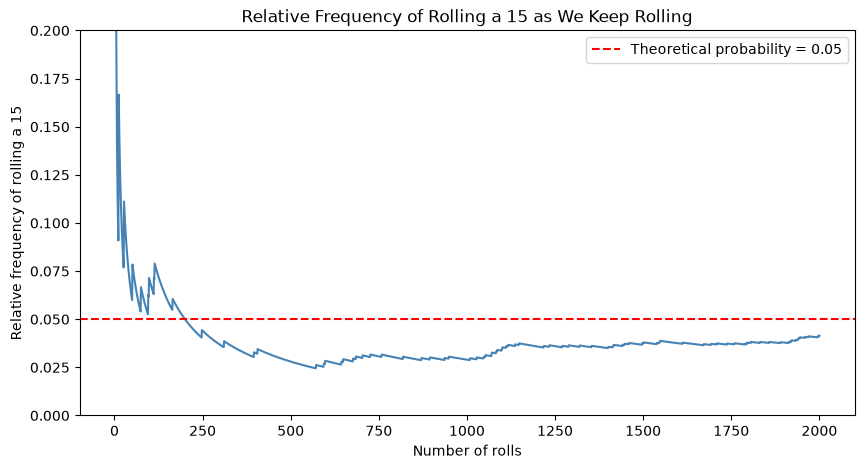

In [37]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=rolls, x="roll_number", y="relative_freq_so_far", color="steelblue")
plt.axhline(0.05, color="red", linestyle="--", label="Theoretical probability = 0.05")

plt.title("Relative Frequency of Rolling a 15 as We Keep Rolling")
plt.xlabel("Number of rolls")
plt.ylabel("Relative frequency of rolling a 15")
plt.ylim(0, 0.2)  # Zoomed to 0–20% for better visual clarity around 5%
plt.legend()
plt.show()

In [38]:
all_runs = []

for run in range(1, 6):
    one_run = roll_dice(2000)
    # Calculate running hits (1 when value is 15, 0 otherwise)
    hits_so_far = (one_run["value"] == 15).astype(int).cumsum()
    one_run["relative_freq_so_far"] = hits_so_far / one_run["roll_number"]
    one_run["run"] = f"Run {run}"
    all_runs.append(one_run)

all_runs = pd.concat(all_runs, ignore_index=True)

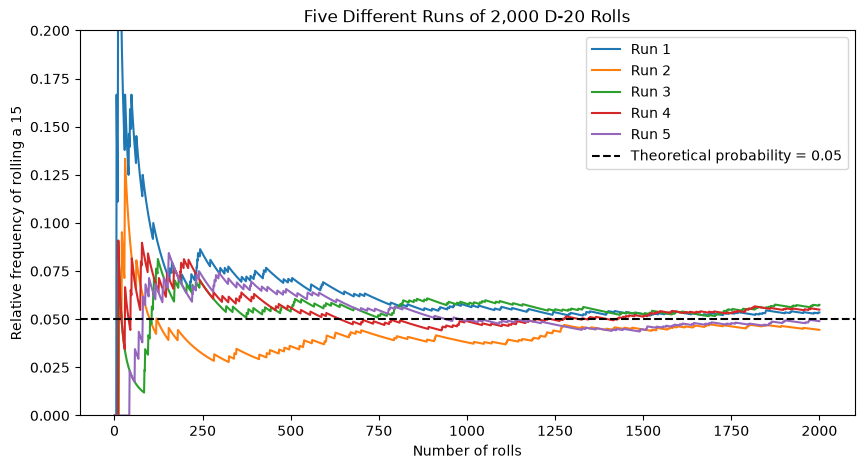

In [40]:
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=all_runs,
    x="roll_number",
    y="relative_freq_so_far",
    hue="run",
    palette="tab10",
)
plt.axhline(
    0.05, color="black", linestyle="--", label="Theoretical probability = 0.05"
)

plt.title("Five Different Runs of 2,000 D-20 Rolls")
plt.xlabel("Number of rolls")
plt.ylabel("Relative frequency of rolling a 15")
plt.ylim(0, 0.2)  # Zoomed to 0–20% for visual clarity around 5%
plt.legend()
plt.show()

In [41]:
rng = np.random.default_rng()
number_of_trials = 10_000
ten_rolls = rng.integers(1, 21, size=(number_of_trials, 10))

In [42]:
hits_per_trial = (ten_rolls == 15).sum(axis=1)
simulated = (hits_per_trial >= 1).mean()
theoretical = 1 - (19 / 20) ** 10

In [43]:
print(f"Simulated P(at least one 15 in 10 rolls): {simulated:.4f}")
print(f"Using the complement rule:              {theoretical:.4f}")

Simulated P(at least one 15 in 10 rolls): 0.4032
Using the complement rule:              0.4013


## Conclusion

The theoretical probability on a standard 20-sided die (D-20) has a sample space of 20 equally likely outcomes because the number 15 appears on exactly one face, the theoretical probability of rolling a 15 is about 5% chance. When rolling 10 dice at once, applying the complement rule yields a theoretical probability of rolling at least one 15 is 40.13%. Based on the graphs we can see that that thw relativity frequency if we keep rolling until you get a 15 is around 0.5 because if you keep rolling the number of rolls goes up to 2,000 rolls. But on the graph where we ran it 5 times we can see that it took less time to roll a 15 when it's runned 5 different times, 